The Darcy friction factor $f_D$ is used to calculate the pressure drop for fluid flow in pipes. When flow is laminar (Re < 3000), $f_D$ is given by the equation:

$$
f_D = \frac{64}{\text{Re}}
$$

where Re is the Reynolds number. When flow is turbulent (Re > 3000), $f_D$ is given by the Colebrook-White equation

$$
\frac{1}{\sqrt{f_D}} = -2.0\ \text{log}_{10}\left(\frac{\epsilon}{3.8}+\frac{2.51}{\text{Re}\sqrt{f_D}}\right)
$$

where $\epsilon$ is the surface roughness. 

Because the equation for the turbulent case does not admit an analytic solution, it must be solved numerically. Before computers became ubiquitious, the solutions were typically present in chart form. These charts are known as Moody charts. You may have seen these in your Transport class.

Your task is to write a program that generates the following Moody chart:

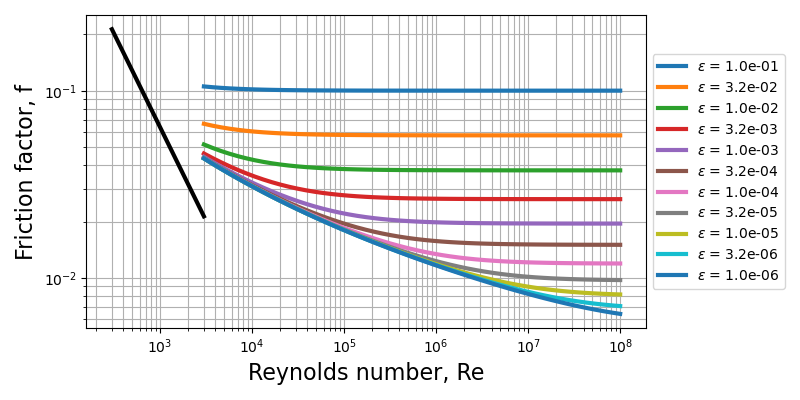

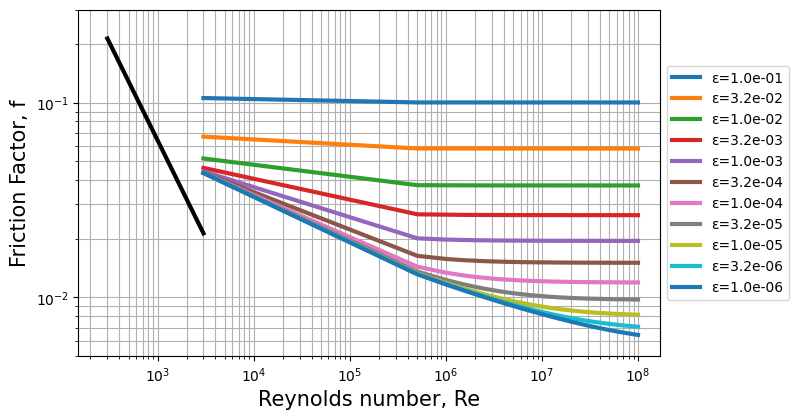

In [163]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt


x = np.linspace(3000, 1e8 ,200)
e_roughness = np.array([1.0e-01,3.2e-02,1.0e-02,3.2e-03,1.0e-03,3.2e-04,1.0e-04,3.2e-05,1.0e-05,3.2e-06,1.0e-06])

def DarcyFF(x,e,F):
    Y = (-1/(F**(1/2)))+(-2.0*np.log10((e/3.8)+(2.51/(x*(F**(1/2))))))
    return Y

plt.figure(figsize=(7.5,4.5))
for e in e_roughness:
    friction = []
    name = "ε=%0.1e" % e
    for re in x:
        Guess = 0.01
        z = opt.fsolve(lambda F: DarcyFF (re,e,F), Guess)
        friction.append(z[0])
    plt.loglog(x,friction, lw = 3, label = name)
    plt.grid(True, which = 'both')
    plt.ylim(0.005,.3)
    plt.xlim(left=150)
    plt.xlabel('Reynolds number, Re', fontsize = 15 )
    plt.ylabel('Friction Factor, f', fontsize = 15)
    plt.legend(bbox_to_anchor=(1,0.5),fontsize=10,loc='center left')

x2 = np.linspace(300,3000, 100)

y = 64/x2
plt.plot(x2,y, lw = 3, color = 'black' )